# ViGoEmotions — Phân tích dữ liệu midterm
Chỉ xuất bảng tổng hợp và biểu đồ. Ma trận đồng xuất hiện/tương quan chỉ dùng train đã loại trùng.

## Kiểm tra môi trường
Chọn kernel **Python (ViGoEmotions)** (`ViGoEmotions/.venv/bin/python`), rồi **Restart Kernel → Run All**. Cell dưới kiểm tra dependency trước khi xử lý dữ liệu.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from check_environment import check_environment
check_environment()

Python kernel: /Users/mac/Documents/Studyspace/2026-2027/Semester_1/ATI/ViGoEmotions/.venv/bin/python
numpy: 2.5.4
scipy: 1.18.1
scikit-learn: 1.9.1


NumPy / SciPy / scikit-learn imports: OK


In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'scripts').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
from IPython.display import display, Image


In [3]:
from analyze_data import main
main()

split  samples  cardinality_mean  cardinality_max  neutral_only  neutral_mixed  repeated_label_rows
train    16530          1.858621                5           570            251                    0
  val     2066          1.870281                5            75             19                    0
 test     2067          1.850992                5            80             36                    1
Excluded training IDs: ['1698']


## Chất lượng dữ liệu và 27 nhãn
Neutral riêng lẻ → vector 0. Neutral + emotion → giữ emotion. Các tier là 9 nhãn/tier theo tần suất train, hòa thì theo ID.

In [4]:
display(pd.read_csv(ROOT/'reports/tables/dataset_summary.csv'))
display(pd.read_csv(ROOT/'reports/tables/label_frequency.csv'))

,split,samples,cardinality_mean,cardinality_max,neutral_only,neutral_mixed,repeated_label_rows
0,train,16530,1.858621,5,570,251,0
1,val,2066,1.870281,5,75,19,0
2,test,2067,1.850992,5,80,36,1


,label_id,label,train_count,train_prevalence,val_count,val_prevalence,test_count,test_prevalence,tier,val_drift_pp,test_drift_pp
0,0,amusement,2868,0.173503,327,0.158277,374,0.180939,head,-1.522586,0.743584
1,1,excitement,824,0.049849,91,0.044046,98,0.047412,mid,-0.580229,-0.243705
2,2,joy,1614,0.097641,168,0.081317,204,0.098694,head,-1.632410,0.105311
3,3,love,1175,0.071083,148,0.071636,143,0.069182,head,0.055313,-0.190049
4,4,desire,762,0.046098,102,0.049371,80,0.038703,tail,0.327276,-0.739457
5,5,optimism,1046,0.063279,122,0.059051,142,0.068699,mid,-0.422758,0.541971
6,6,caring,1062,0.064247,131,0.063408,150,0.072569,head,-0.083927,0.832212
7,7,pride,774,0.046824,87,0.042110,86,0.041606,mid,-0.471360,-0.521776
8,8,admiration,883,0.053418,107,0.051791,101,0.048863,mid,-0.162713,-0.455494
9,9,gratitude,765,0.046279,96,0.046467,108,0.052250,mid,0.018711,0.597015


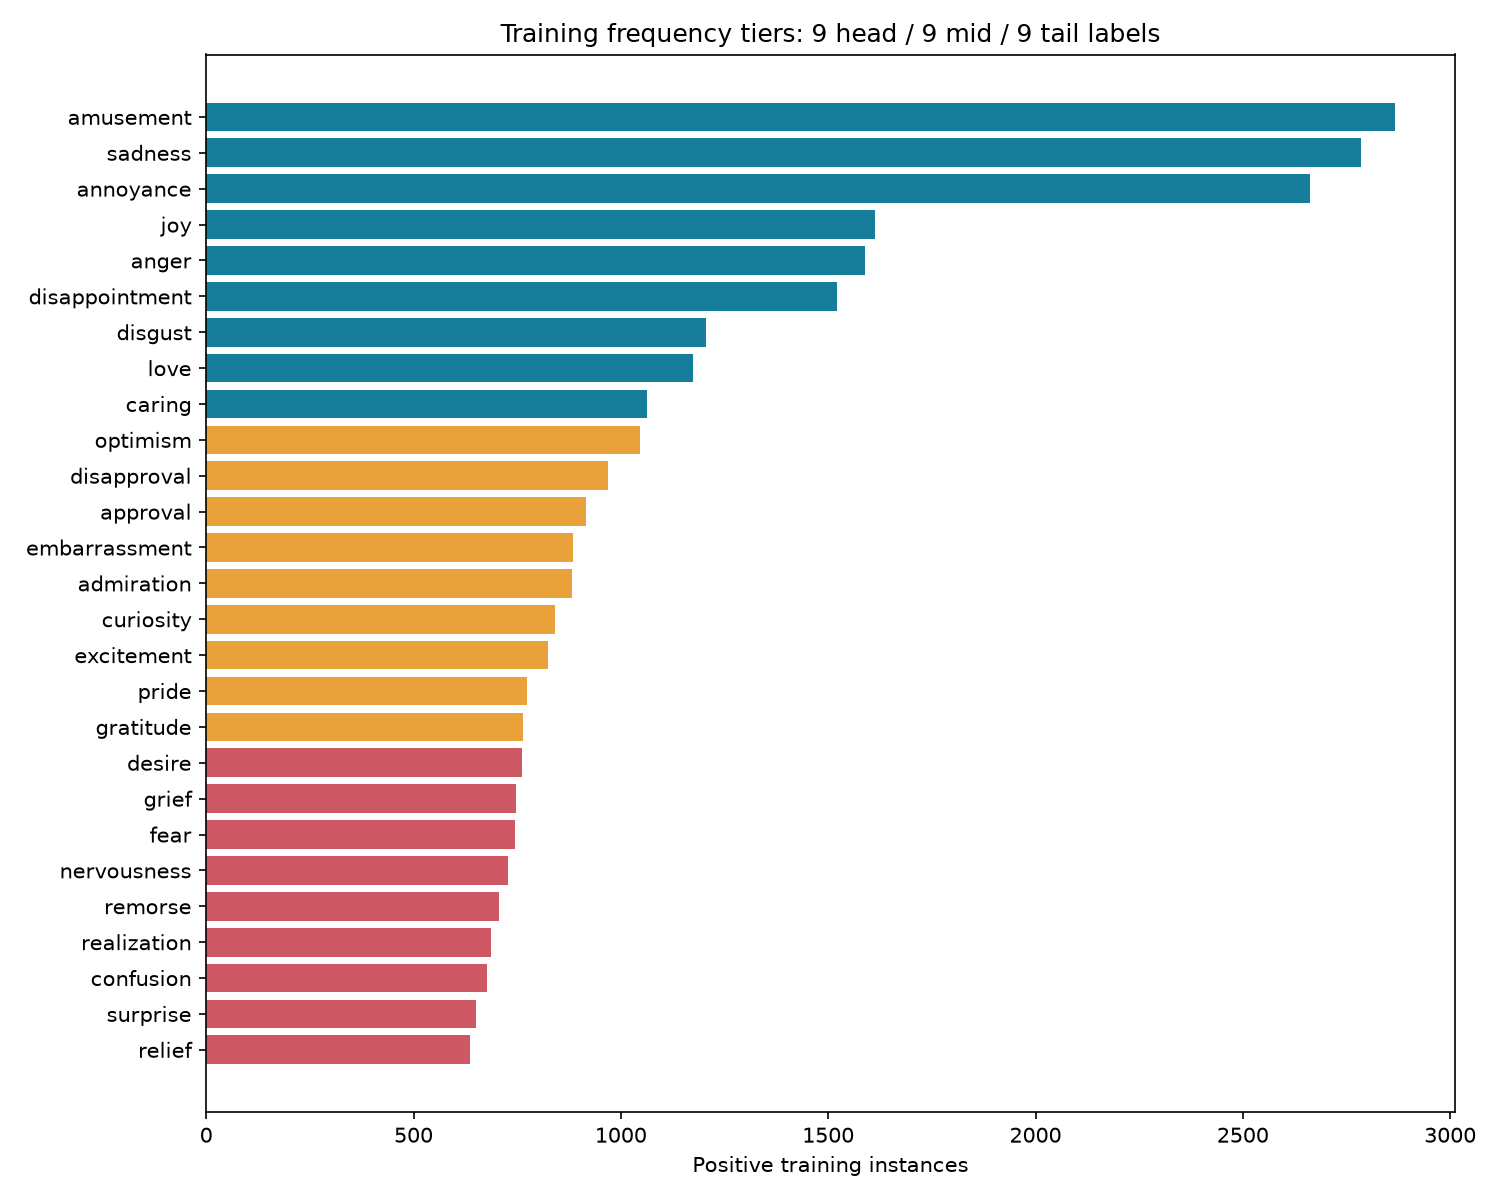

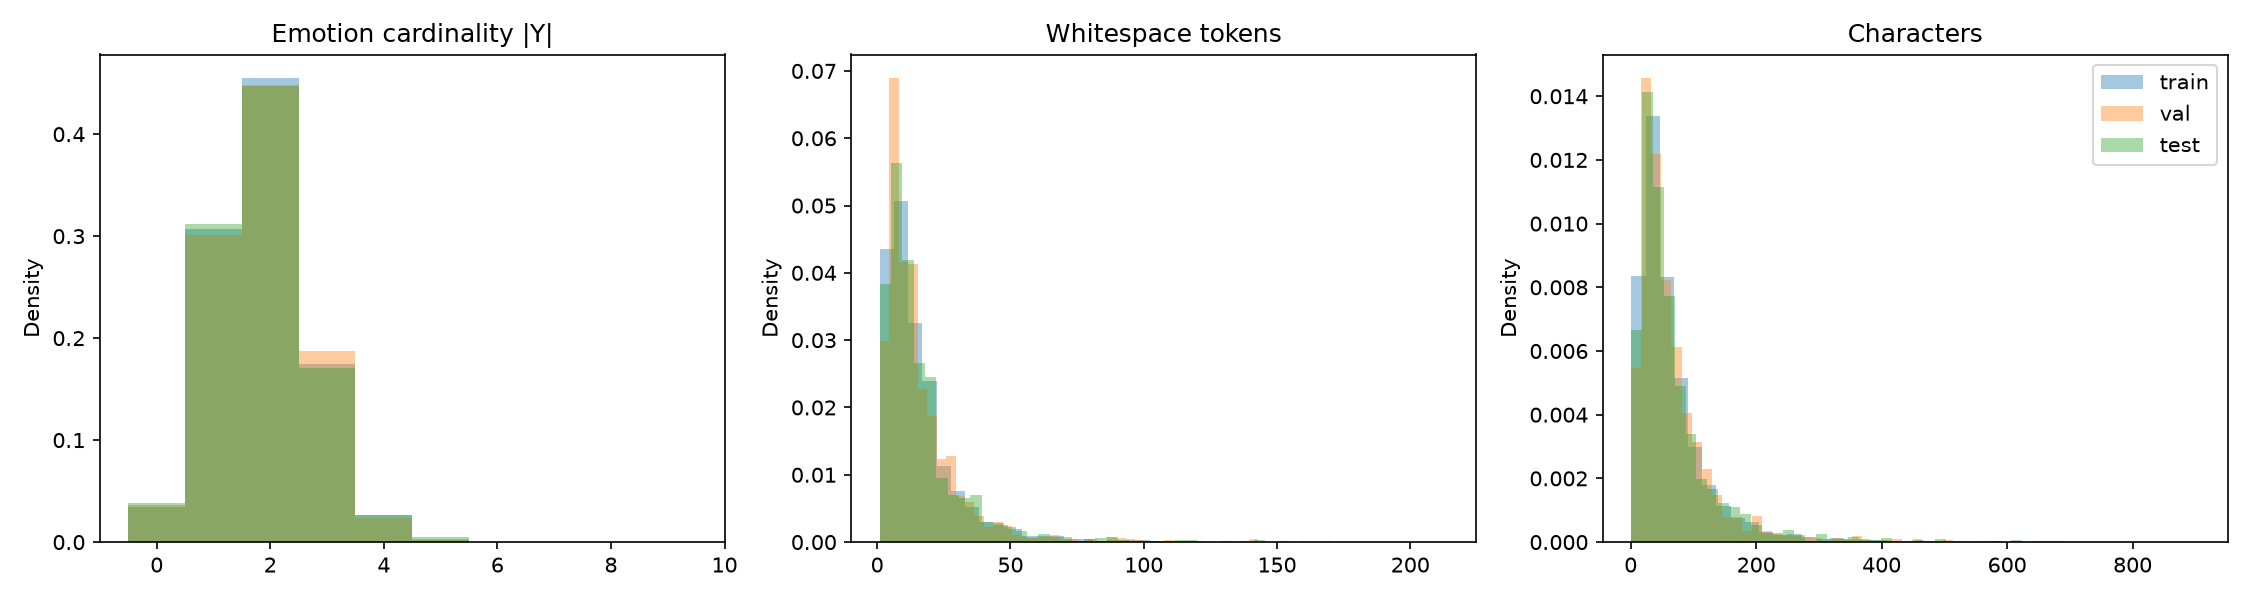

In [5]:
display(Image(filename=str(ROOT/'reports/figures/label_frequency.png')))
display(Image(filename=str(ROOT/'reports/figures/distributions.png')))

## Phụ thuộc nhãn — chỉ train

,label_a,label_b,count,phi
0,disappointment,sadness,904,0.361998
1,anger,annoyance,699,0.247411
2,sadness,grief,620,0.384491
3,amusement,joy,568,0.154985
4,annoyance,disapproval,469,0.219260
5,joy,love,395,0.222296
6,disgust,anger,379,0.207602
7,embarrassment,sadness,366,0.155731
8,excitement,joy,359,0.260851
9,amusement,annoyance,336,-0.054704


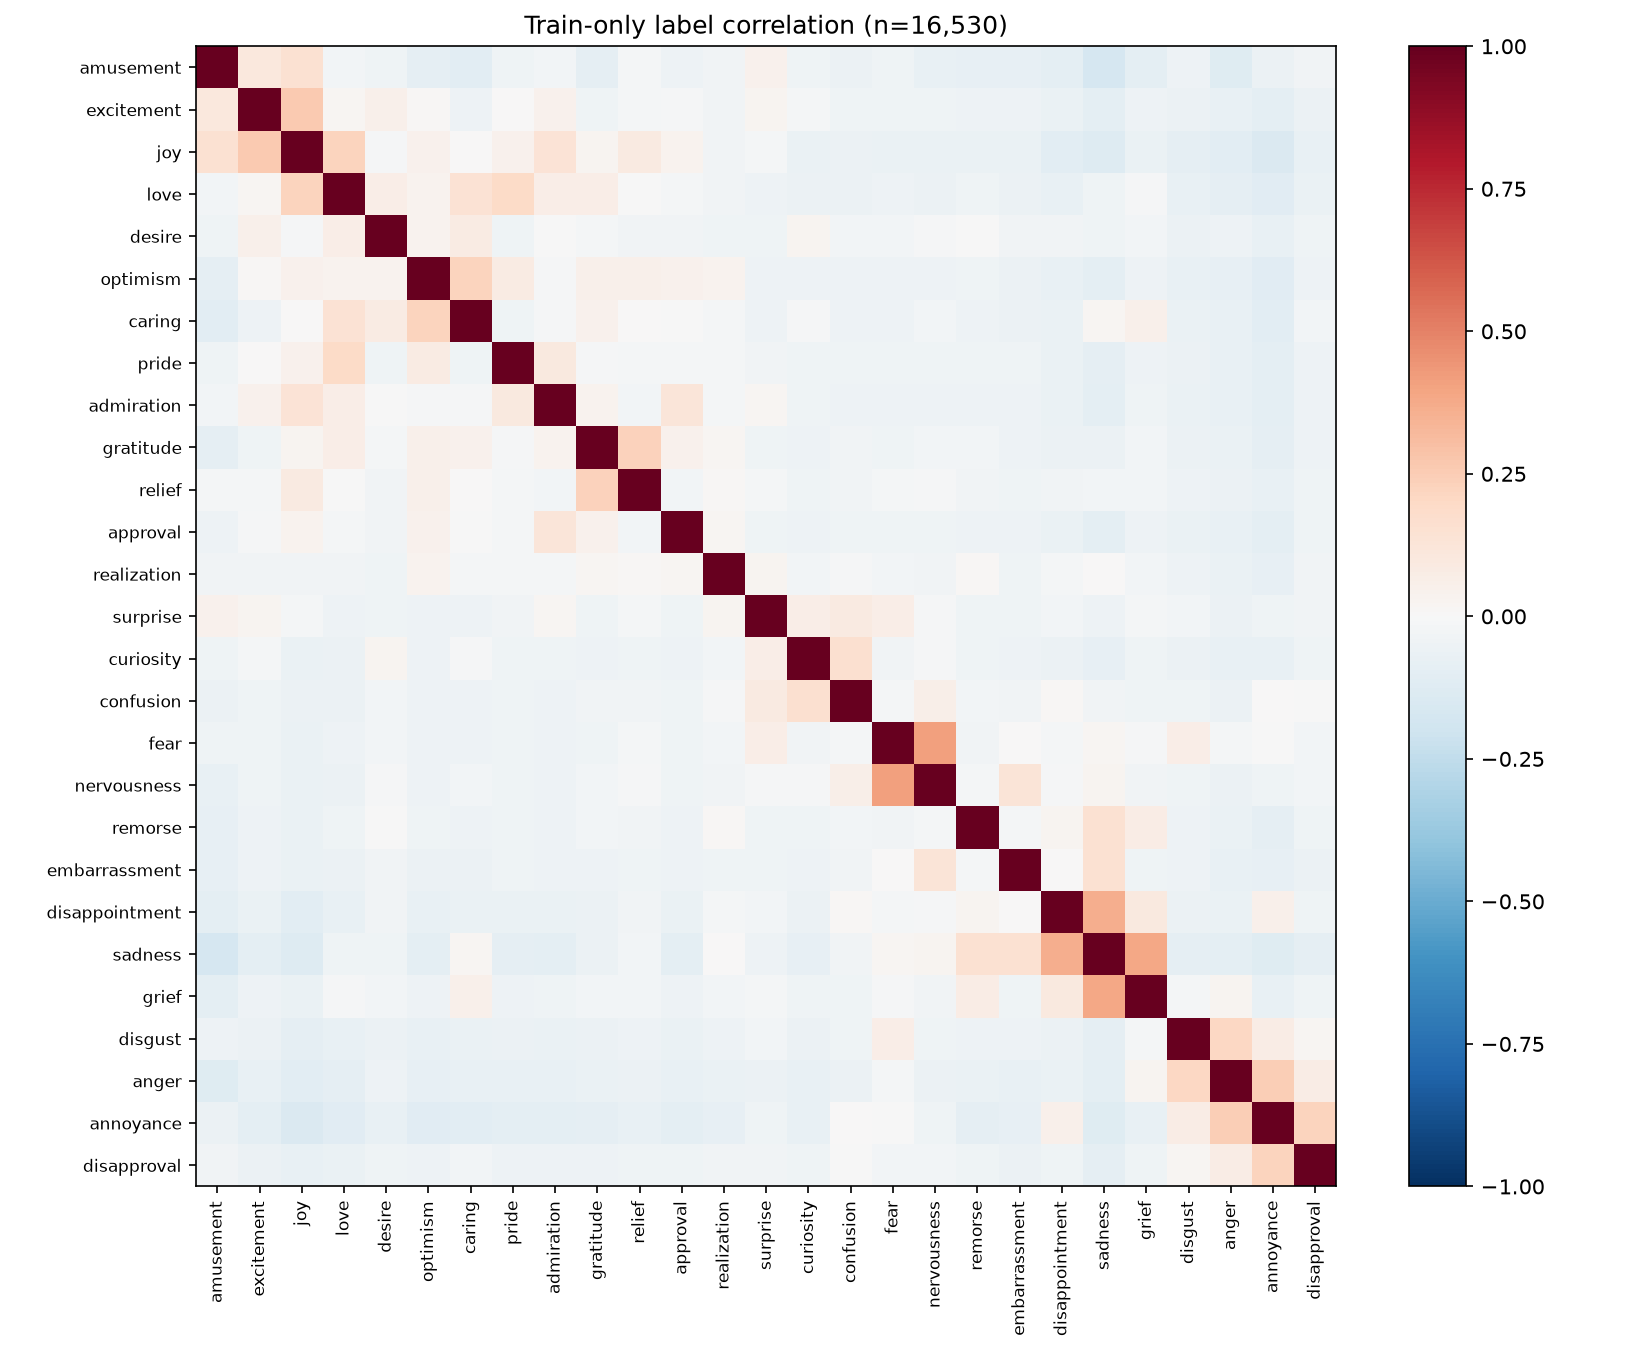

In [6]:
display(pd.read_csv(ROOT/'reports/tables/train_top_pairs.csv').head(10))
display(Image(filename=str(ROOT/'reports/figures/train_correlation.png')))

## Độ dài, phong cách và split
Whitespace tokens không phải từ đã tách theo ngôn ngữ học. Nhóm teencode/emoji là heuristic, có thể chồng lấn. Giữ split được cung cấp; audit tỷ lệ biên không chứng minh thuật toán stratification ban đầu.

In [7]:
display(pd.read_csv(ROOT/'reports/tables/text_lengths.csv'))
display(pd.read_csv(ROOT/'reports/tables/text_styles.csv'))

,split,unit,mean,median,p95,p99,minimum,maximum
0,train,whitespace_tokens,16.055051,11.0,44.00,84.00,1,214
1,train,characters,66.432002,47.0,185.00,353.42,1,906
2,val,whitespace_tokens,16.059535,12.0,44.00,88.00,1,143
3,val,characters,66.480155,47.0,187.75,363.40,1,641
4,test,whitespace_tokens,16.820029,11.0,47.00,90.68,1,171
5,test,characters,69.460087,47.0,193.70,380.04,1,693


,split,style,count,proportion
0,train,all,16530,1.000000
1,train,short_le_5,2804,0.169631
2,train,emoji_heavy_ge_2,1578,0.095463
3,train,teencode,5695,0.344525
4,val,all,2066,1.000000
5,val,short_le_5,343,0.166021
6,val,emoji_heavy_ge_2,199,0.096321
7,val,teencode,726,0.351404
8,test,all,2067,1.000000
9,test,short_le_5,337,0.163038
